In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [60]:
url_red = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df_red = pd.read_csv(url_red, sep=';')

url_white = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
df_white = pd.read_csv(url_red, sep=';')

df_red['is_red'] = 1
df_white['is_red'] = 0

df = pd.concat([df_red, df_white], ignore_index=True)

print(df.shape)
df.head()

(3198, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [67]:
f'{round(float(df.duplicated().sum() / df.shape[0]), 2) * 100} %'

'15.0 %'

In [72]:
stats = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = df.skew()
stats['kurtosis'] = df.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
fixed acidity,8.319637,1.740824,4.60000,7.90000,15.90000,0.982290,1.128496
volatile acidity,0.527821,0.179032,0.12000,0.52000,1.58000,0.671277,1.221748
citric acid,0.270976,0.194771,0.00000,0.26000,1.00000,0.318188,-0.789641
residual sugar,2.538806,1.409708,0.90000,2.20000,15.50000,4.538524,28.570964
chlorides,0.087467,0.047058,0.01200,0.07900,0.61100,5.677680,41.648672
free sulfur dioxide,15.874922,10.458521,1.00000,14.00000,72.00000,1.249980,2.018520
total sulfur dioxide,46.467792,32.890179,6.00000,38.00000,289.00000,1.514820,3.801989
density,0.996747,0.001887,0.99007,0.99675,1.00369,0.071254,0.930741
pH,3.311113,0.154362,2.74000,3.31000,4.01000,0.193593,0.803803
sulphates,0.658149,0.169480,0.33000,0.62000,2.00000,2.427532,11.700044


In [69]:
X = df.drop(columns=['quality'])
y = df['quality']

<Axes: xlabel='quality', ylabel='Count'>

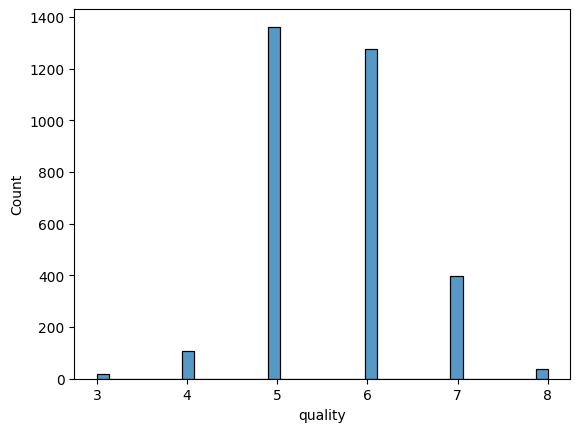

In [ ]:
sns.histplot(y)

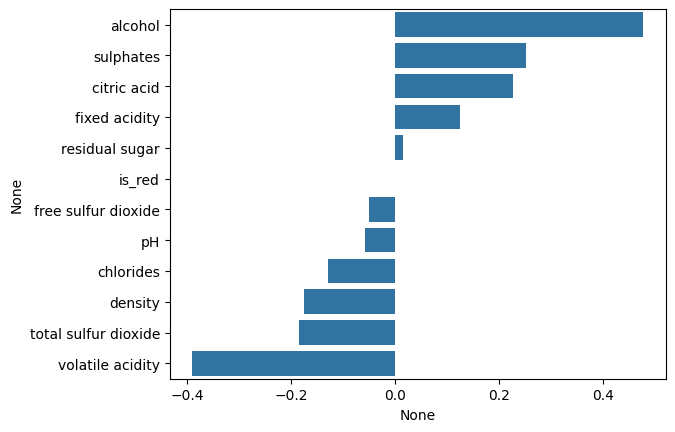

In [ ]:
correlations = X.corrwith(y).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)

<Axes: >

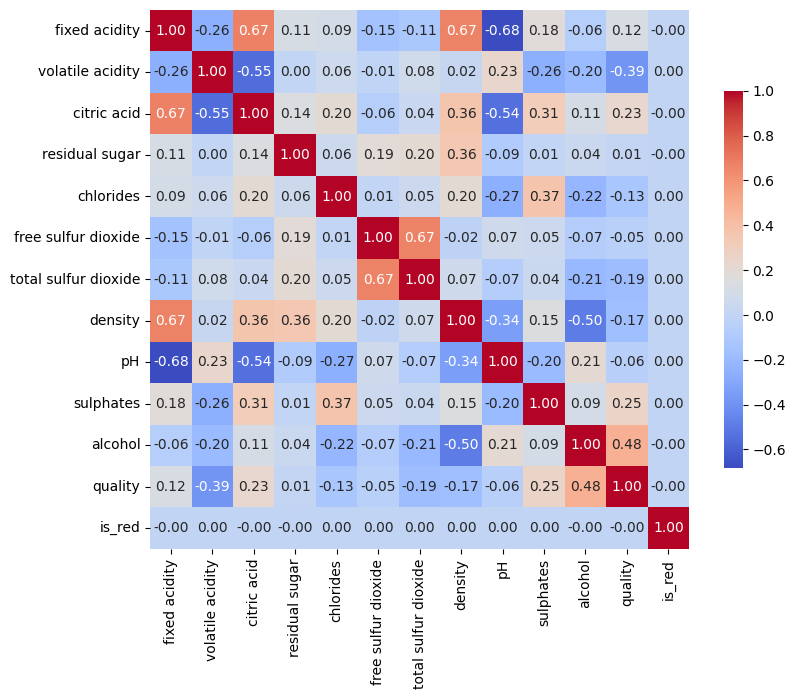

In [ ]:
corr_matrix = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})